In [1]:
# ── Configuration ──────────────────────────────────────────────────────────
# Edit RAW_DATA_PATH to point to the raw CSV.
# The encoded output will be saved next to it automatically.
from pathlib import Path

RAW_DATA_PATH     = Path("archive/spotify-tracks-dataset.csv")
ENCODED_DATA_PATH = RAW_DATA_PATH.parent / "spotify_encoded.csv"

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Raw dataset not found at '{RAW_DATA_PATH.resolve()}'.\n"
        "Update RAW_DATA_PATH above."
    )

print("Raw data  :", RAW_DATA_PATH.resolve())
print("Output CSV:", ENCODED_DATA_PATH.resolve())

Raw data  : D:\entc_ml_project-master\entc_ml_project-master\archive\spotify-tracks-dataset.csv
Output CSV: D:\entc_ml_project-master\entc_ml_project-master\archive\spotify_encoded.csv


In [2]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder

%matplotlib inline
sns.set_theme(style="whitegrid")

In [3]:
# ── Load & basic inspection ────────────────────────────────────────────────
df = pd.read_csv(RAW_DATA_PATH)
print(f"Raw shape: {df.shape}")

# Drop unnamed artefact columns from CSV export
unnamed = [c for c in df.columns if c.startswith("Unnamed")]
df.drop(columns=unnamed, inplace=True)

# Drop non-feature identifier columns
id_cols = [c for c in ["track_id", "artists", "album_name", "track_name"] if c in df.columns]
df.drop(columns=id_cols, inplace=True)

# Drop nulls and duplicates
before = len(df)
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
print(f"Removed {before - len(df)} null / duplicate rows.")

# Remove physically impossible values
broken = (
    (df["duration_ms"]    <= 0)
    | (df["tempo"]         <= 0)
    | (df["loudness"]      >  0)
    | (df["time_signature"] < 3)
)
before = len(df)
df = df.loc[~broken].copy()
print(f"Removed {before - len(df)} rows with invalid values.")
print(f"Working shape: {df.shape}")
df.info()

Raw shape: (114000, 22)
Removed 7093 null / duplicate rows.
Removed 1176 rows with invalid values.
Working shape: (105731, 16)
<class 'pandas.DataFrame'>
Index: 105731 entries, 0 to 113999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   popularity        105731 non-null  int64  
 1   duration_ms       105731 non-null  int64  
 2   explicit          105731 non-null  bool   
 3   danceability      105731 non-null  float64
 4   energy            105731 non-null  float64
 5   key               105731 non-null  int64  
 6   loudness          105731 non-null  float64
 7   mode              105731 non-null  int64  
 8   speechiness       105731 non-null  float64
 9   acousticness      105731 non-null  float64
 10  instrumentalness  105731 non-null  float64
 11  liveness          105731 non-null  float64
 12  valence           105731 non-null  float64
 13  tempo             105731 non-null  float64
 14  time_

In [4]:
# ════════════════════════════════════════════════════════════════════════════
# 1.  Binary Encoding — explicit  (True/False → 1/0)
# ════════════════════════════════════════════════════════════════════════════
print("Before encoding:")
print(df["explicit"].value_counts())

df["explicit"] = df["explicit"].astype(int)

print("\nAfter encoding:")
print(df["explicit"].value_counts())

Before encoding:
explicit
False    96735
True      8996
Name: count, dtype: int64

After encoding:
explicit
0    96735
1     8996
Name: count, dtype: int64


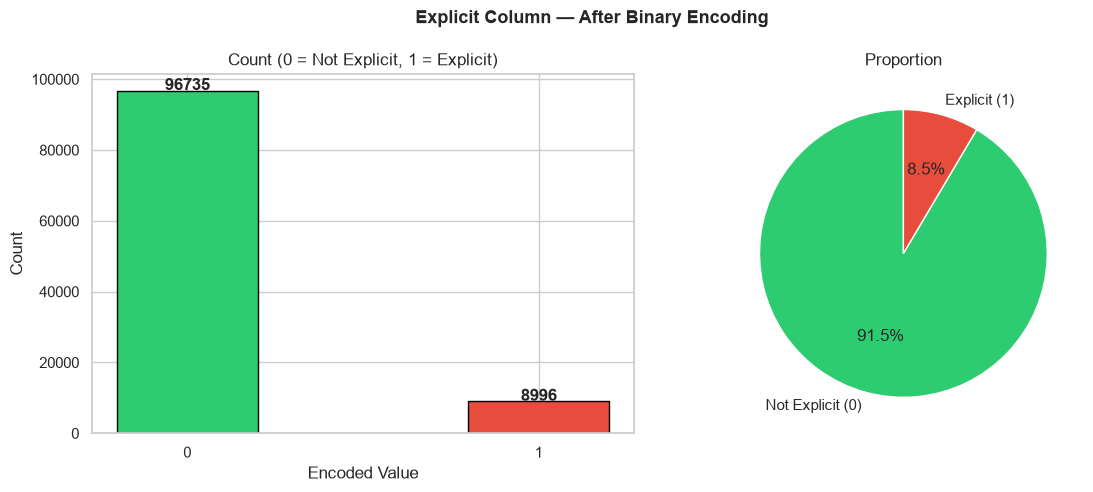

In [5]:
# ── Viz: explicit distribution ─────────────────────────────────────────────
counts = df["explicit"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Explicit Column — After Binary Encoding", fontsize=13, fontweight="bold")

bars = axes[0].bar(counts.index.astype(str), counts.values,
                   color=["#2ecc71", "#e74c3c"], edgecolor="black", width=0.4)
axes[0].set_title("Count (0 = Not Explicit, 1 = Explicit)")
axes[0].set_xlabel("Encoded Value")
axes[0].set_ylabel("Count")
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200,
                 str(int(bar.get_height())), ha="center", fontweight="bold")

axes[1].pie(counts.values, labels=["Not Explicit (0)", "Explicit (1)"],
            autopct="%1.1f%%", colors=["#2ecc71", "#e74c3c"], startangle=90)
axes[1].set_title("Proportion")

plt.tight_layout()
plt.show()

In [6]:
# ════════════════════════════════════════════════════════════════════════════
# 2.  One-Hot Encoding — track_genre  (sklearn OneHotEncoder)
# ════════════════════════════════════════════════════════════════════════════
print(f"Unique genres before encoding: {df['track_genre'].nunique()}")
print(df["track_genre"].value_counts().head(10))

Unique genres before encoding: 114
track_genre
mandopop          999
cantopop          998
samba             997
chicago-house     996
forro             996
j-idol            996
heavy-metal       995
detroit-techno    994
gospel            994
sertanejo         994
Name: count, dtype: int64


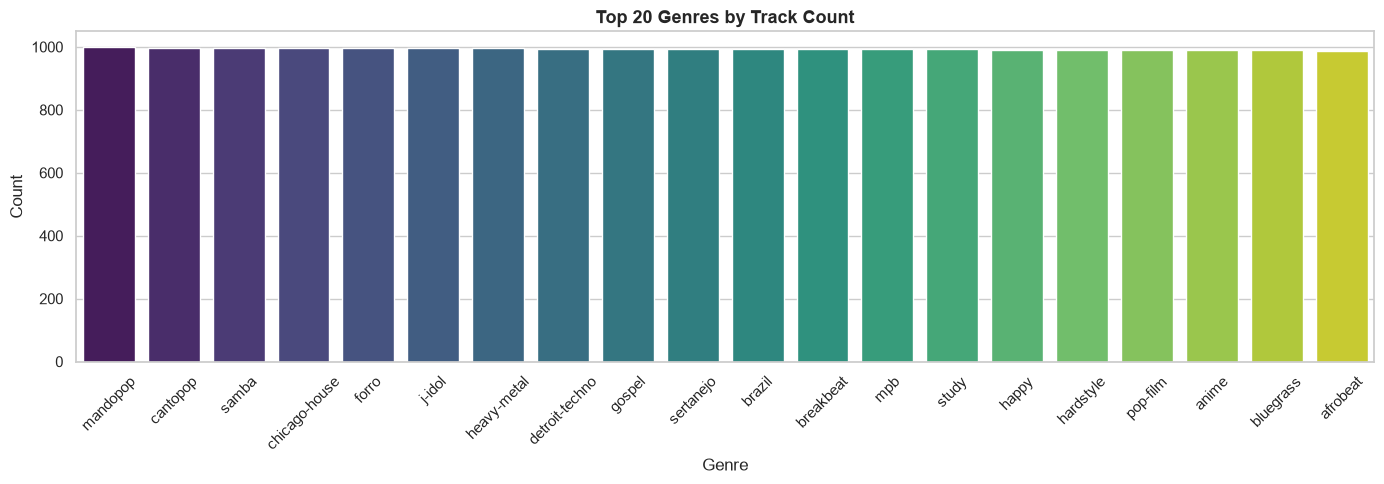

In [7]:
# ── Viz: top 20 genres ────────────────────────────────────────────────────
top_genres = df["track_genre"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(x=top_genres.index, y=top_genres.values, palette="viridis", ax=ax)
ax.set_title("Top 20 Genres by Track Count", fontsize=13, fontweight="bold")
ax.set_xlabel("Genre")
ax.set_ylabel("Count")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# ── Apply OHE ─────────────────────────────────────────────────────────────
ohe           = OneHotEncoder(sparse_output=False)
genre_encoded = ohe.fit_transform(df[["track_genre"]])
genre_cols    = ohe.get_feature_names_out(["track_genre"])
genre_df      = pd.DataFrame(genre_encoded, columns=genre_cols, index=df.index)

df = pd.concat([df.drop(columns=["track_genre"]), genre_df], axis=1)
print(f"Shape after one-hot encoding: {df.shape}")
print(f"Genre columns (first 10): {list(genre_cols[:10])}")

Shape after one-hot encoding: (105731, 129)
Genre columns (first 10): ['track_genre_acoustic', 'track_genre_afrobeat', 'track_genre_alt-rock', 'track_genre_alternative', 'track_genre_ambient', 'track_genre_anime', 'track_genre_black-metal', 'track_genre_bluegrass', 'track_genre_blues', 'track_genre_brazil']


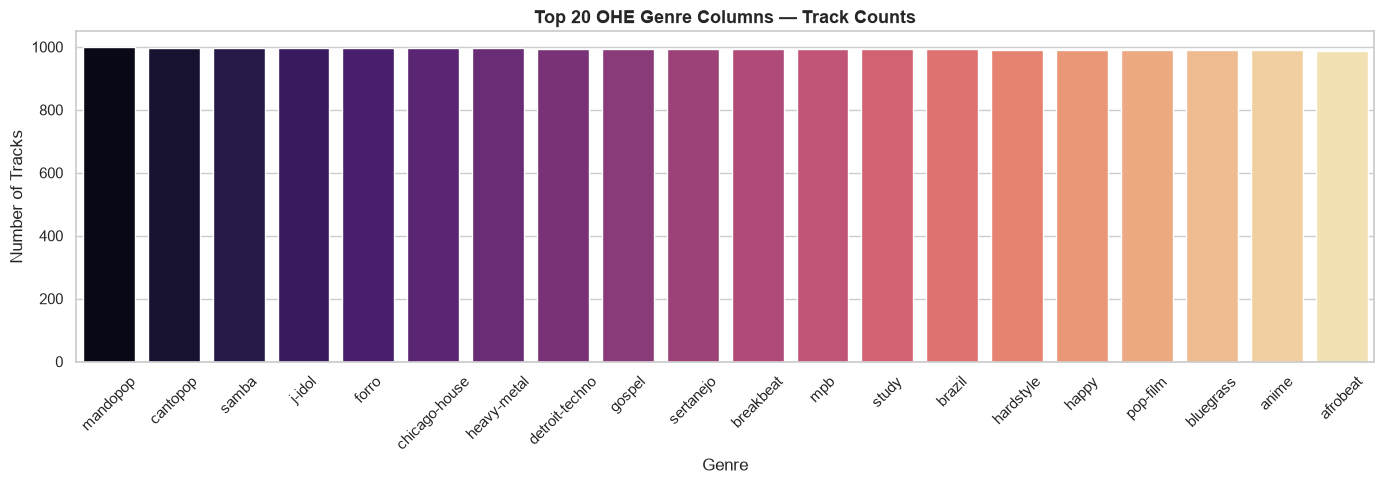

In [9]:
# ── Viz: encoded genre column sums ────────────────────────────────────────
genre_sums = genre_df.sum().sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(x=genre_sums.index.str.replace("track_genre_", ""),
            y=genre_sums.values, palette="magma", ax=ax)
ax.set_title("Top 20 OHE Genre Columns — Track Counts", fontsize=13, fontweight="bold")
ax.set_xlabel("Genre")
ax.set_ylabel("Number of Tracks")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [10]:
# ════════════════════════════════════════════════════════════════════════════
# 3.  Skewness Analysis
# ════════════════════════════════════════════════════════════════════════════
audio_features = [
    "popularity", "duration_ms", "explicit", "danceability", "energy",
    "key", "loudness", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "time_signature",
]

skew_vals = df[audio_features].skew().sort_values()
print("Skewness of audio features (before transformation):")
print(skew_vals.to_string())

print("\nStrongly right-skewed (skew > 1) :", skew_vals[skew_vals > 1].index.tolist())
print("Strongly left-skewed  (skew < -1):", skew_vals[skew_vals < -1].index.tolist())

Skewness of audio features (before transformation):
loudness            -1.982808
time_signature      -1.618831
energy              -0.599575
mode                -0.555960
danceability        -0.366559
popularity          -0.006559
key                 -0.003880
valence              0.130580
tempo                0.300324
acousticness         0.741263
instrumentalness     1.679400
liveness             2.090327
explicit             2.974283
speechiness          4.608770
duration_ms         10.641998

Strongly right-skewed (skew > 1) : ['instrumentalness', 'liveness', 'explicit', 'speechiness', 'duration_ms']
Strongly left-skewed  (skew < -1): ['loudness', 'time_signature']


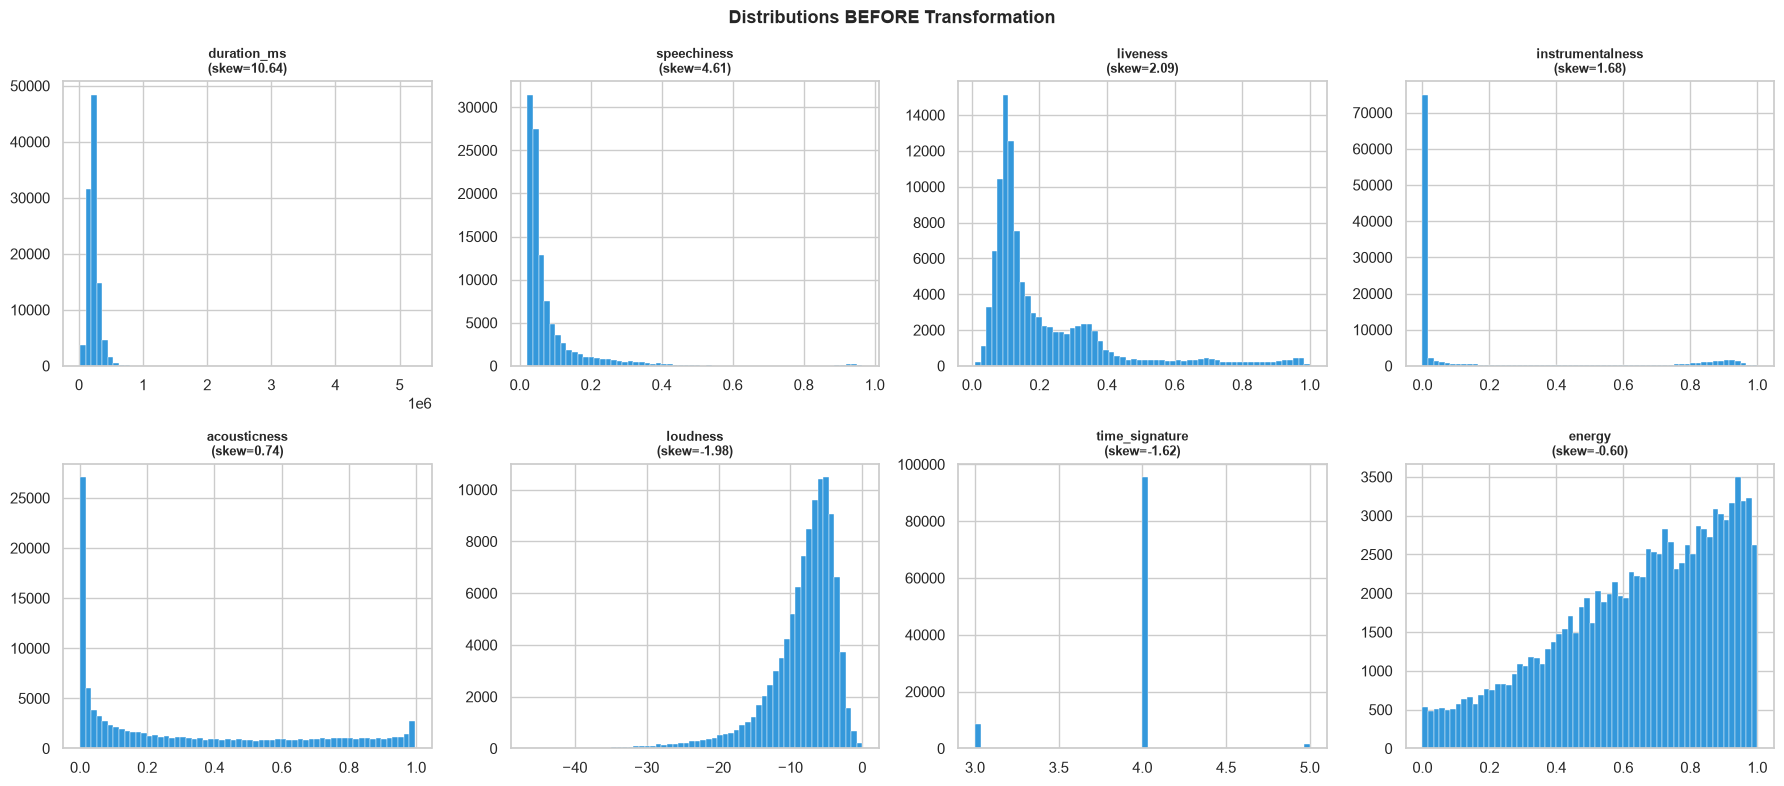

In [11]:
# ── Viz: distributions before transformation ──────────────────────────────
skew_features = ["duration_ms", "speechiness", "liveness", "instrumentalness",
                 "acousticness", "loudness", "time_signature", "energy"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, feat in enumerate(skew_features):
    axes[i].hist(df[feat].dropna(), bins=60, color="#3498db",
                 edgecolor="white", linewidth=0.3)
    axes[i].set_title(f"{feat}\n(skew={df[feat].skew():.2f})",
                      fontsize=9, fontweight="bold")
plt.suptitle("Distributions BEFORE Transformation", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [12]:
# ════════════════════════════════════════════════════════════════════════════
# 4.  Log-Normal Transformations to reduce skewness
# ════════════════════════════════════════════════════════════════════════════
# Right-skewed (skew > 0.5) → log1p
right_skewed = ["duration_ms", "speechiness", "liveness",
                "instrumentalness", "acousticness"]
for feat in right_skewed:
    df[feat] = np.log1p(df[feat])

# Left-skewed (skew < -1) → reflect then log1p
left_skewed = ["loudness", "time_signature", "energy"]
for feat in left_skewed:
    df[feat] = np.log1p(df[feat].max() - df[feat])

print("Applied log1p to:", right_skewed)
print("Applied reflect+log1p to:", left_skewed)

skew_after = df[skew_features].skew().sort_values()
comparison = pd.DataFrame({"Before": skew_vals.reindex(skew_features),
                            "After":  skew_after})
comparison["Improvement"] = comparison["Before"].abs() - comparison["After"].abs()
print("\nSkewness comparison:")
print(comparison.round(3).to_string())

Applied log1p to: ['duration_ms', 'speechiness', 'liveness', 'instrumentalness', 'acousticness']
Applied reflect+log1p to: ['loudness', 'time_signature', 'energy']

Skewness comparison:
                  Before  After  Improvement
acousticness       0.741  0.563        0.178
duration_ms       10.642 -0.316       10.326
energy            -0.600  0.316        0.284
instrumentalness   1.679  1.597        0.082
liveness           2.090  1.726        0.364
loudness          -1.983  0.166        1.817
speechiness        4.609  3.681        0.928
time_signature    -1.619 -0.488        1.131


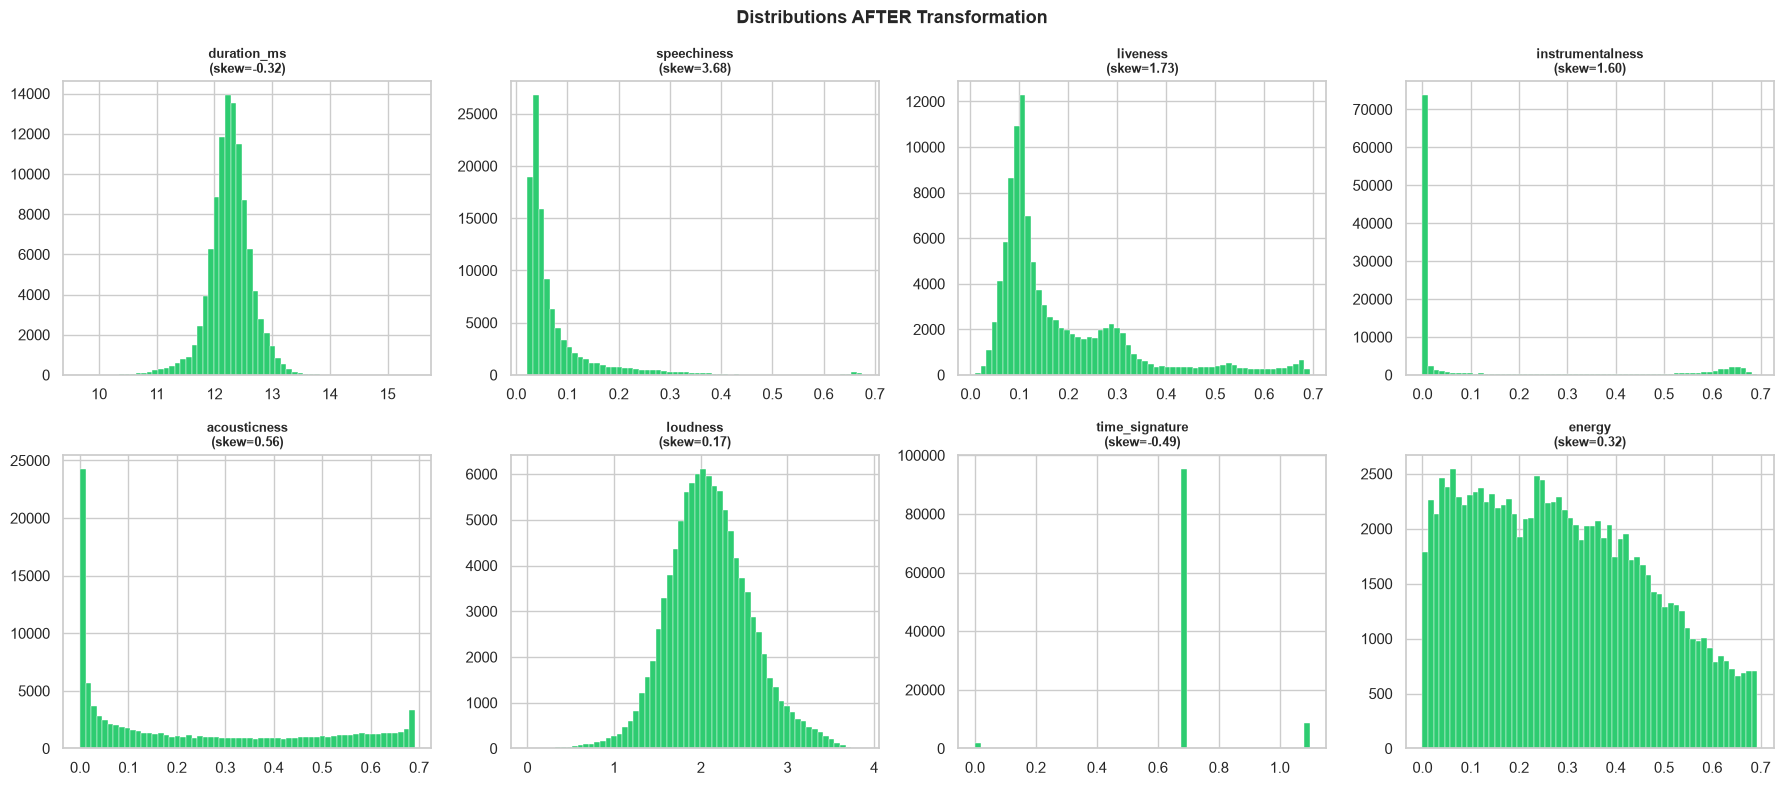

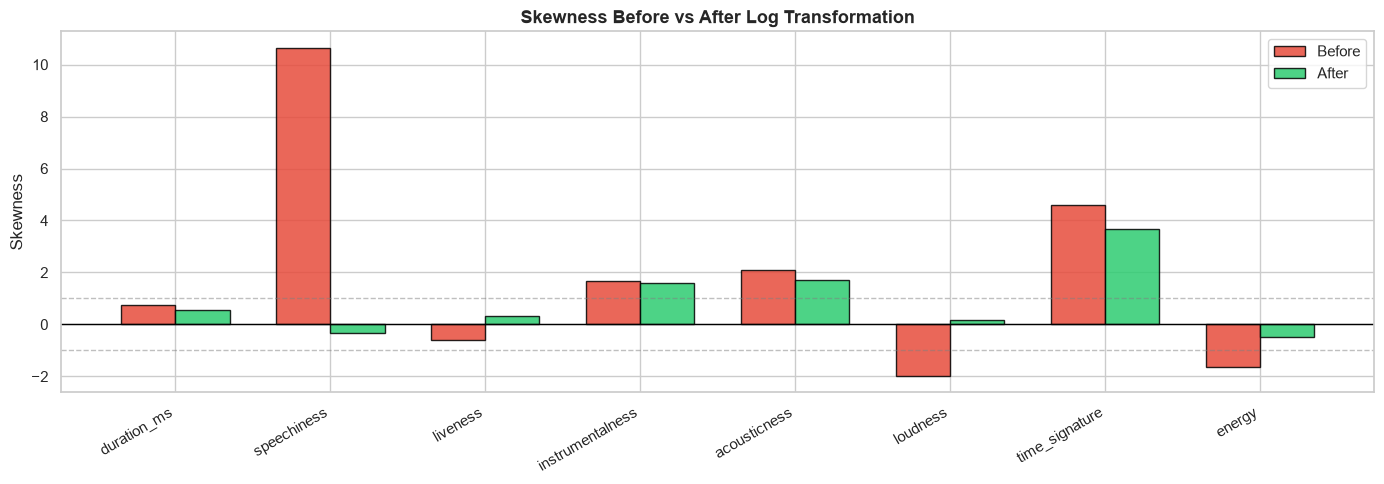

In [13]:
# ── Viz: distributions after transformation ───────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, feat in enumerate(skew_features):
    axes[i].hist(df[feat].dropna(), bins=60, color="#2ecc71",
                 edgecolor="white", linewidth=0.3)
    axes[i].set_title(f"{feat}\n(skew={df[feat].skew():.2f})",
                      fontsize=9, fontweight="bold")
plt.suptitle("Distributions AFTER Transformation", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Before vs After bar chart
x     = np.arange(len(skew_features))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - width/2, comparison["Before"], width, label="Before",
       color="#e74c3c", edgecolor="black", alpha=0.85)
ax.bar(x + width/2, comparison["After"],  width, label="After",
       color="#2ecc71", edgecolor="black", alpha=0.85)
ax.axhline(0,  color="black", linewidth=1)
ax.axhline(1,  color="gray",  linewidth=1, linestyle="--", alpha=0.5)
ax.axhline(-1, color="gray",  linewidth=1, linestyle="--", alpha=0.5)
ax.set_xticks(x)
ax.set_xticklabels(skew_features, rotation=30, ha="right")
ax.set_ylabel("Skewness")
ax.set_title("Skewness Before vs After Log Transformation", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

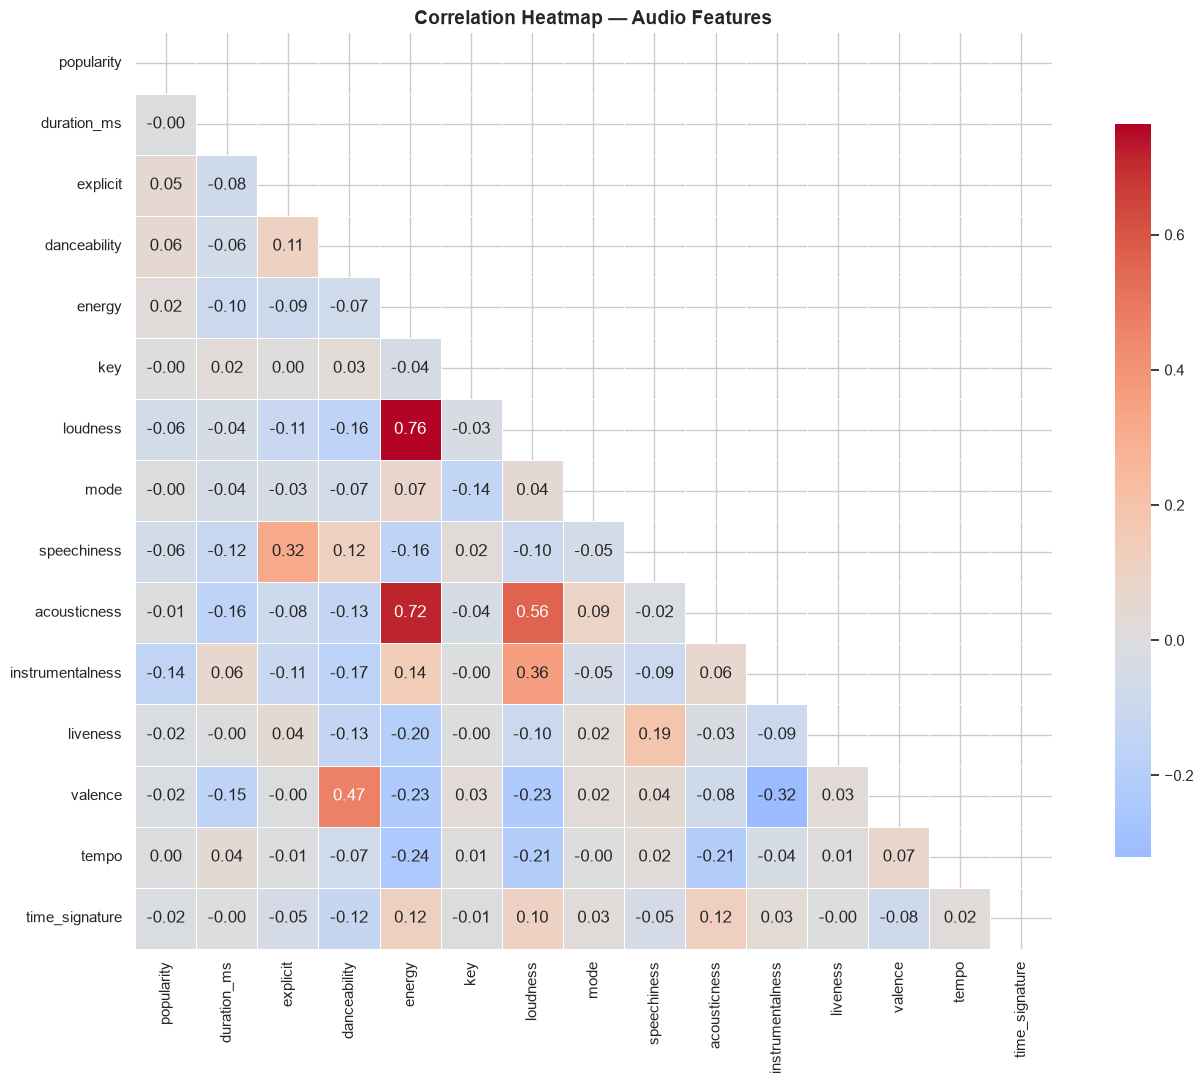

In [14]:
# ════════════════════════════════════════════════════════════════════════════
# 5.  Correlation Analysis
# ════════════════════════════════════════════════════════════════════════════
corr_df = df[audio_features].corr()

# Full heatmap
fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_df, dtype=bool))
sns.heatmap(corr_df, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, linewidths=0.5, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation Heatmap — Audio Features", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

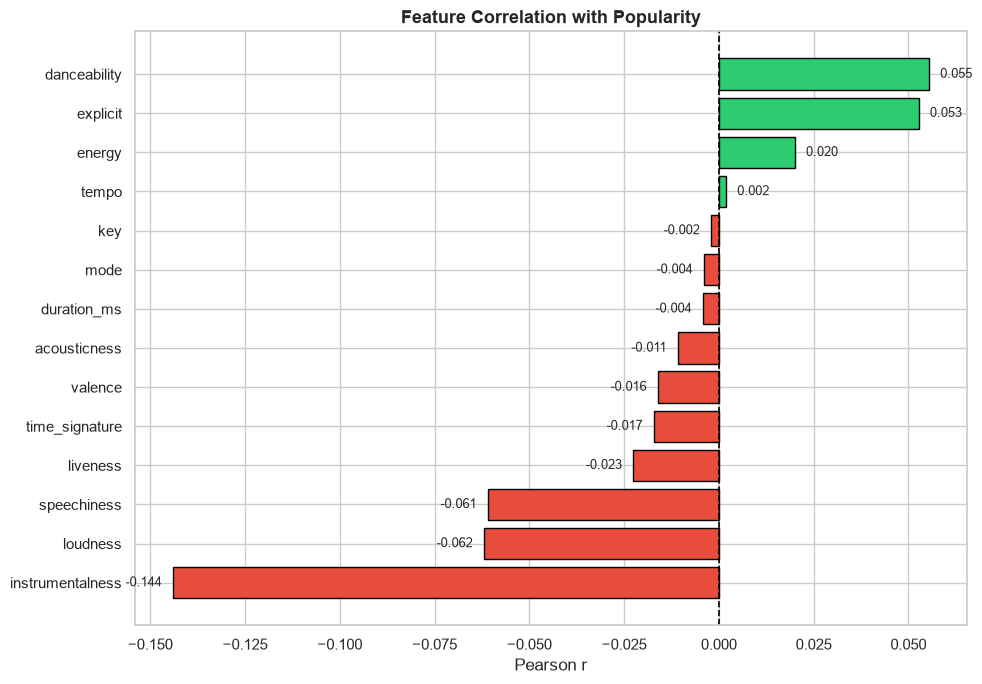

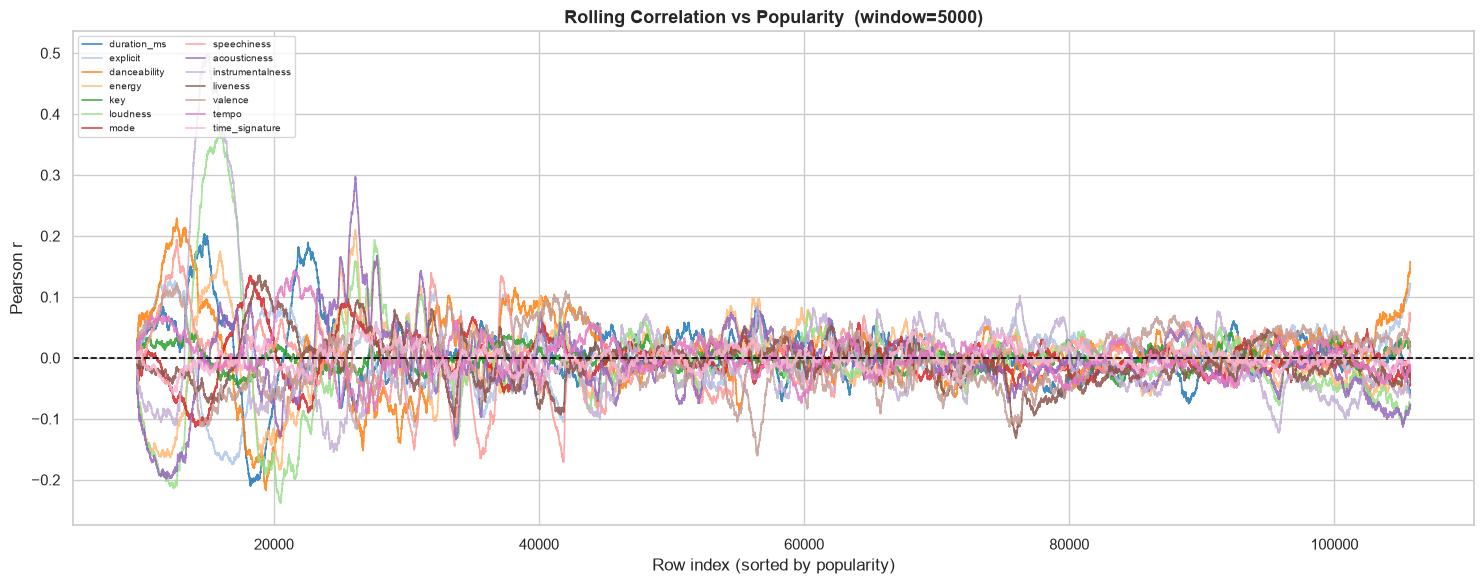

In [15]:
# ── Correlation with popularity ────────────────────────────────────────────
pop_corr = corr_df["popularity"].drop("popularity").sort_values()
colors   = ["#e74c3c" if v < 0 else "#2ecc71" for v in pop_corr.values]

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(pop_corr.index, pop_corr.values, color=colors, edgecolor="black")
ax.axvline(0, color="black", linewidth=1.2, linestyle="--")
ax.set_title("Feature Correlation with Popularity", fontsize=13, fontweight="bold")
ax.set_xlabel("Pearson r")
for bar, val in zip(bars, pop_corr.values):
    ax.text(val + (0.003 if val >= 0 else -0.003),
            bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center",
            ha="left" if val >= 0 else "right", fontsize=9)
plt.tight_layout()
plt.show()

# Rolling correlation curves
sorted_df = df[audio_features].sort_values("popularity").reset_index(drop=True)
window    = 5000

fig, ax = plt.subplots(figsize=(15, 6))
palette  = sns.color_palette("tab20", len(audio_features) - 1)
for col, color in zip([c for c in audio_features if c != "popularity"], palette):
    ax.plot(sorted_df["popularity"].rolling(window).corr(sorted_df[col]),
            label=col, color=color, linewidth=1.2, alpha=0.85)
ax.axhline(0, color="black", linewidth=1.2, linestyle="--")
ax.set_title(f"Rolling Correlation vs Popularity  (window={window})",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Row index (sorted by popularity)")
ax.set_ylabel("Pearson r")
ax.legend(loc="upper left", fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

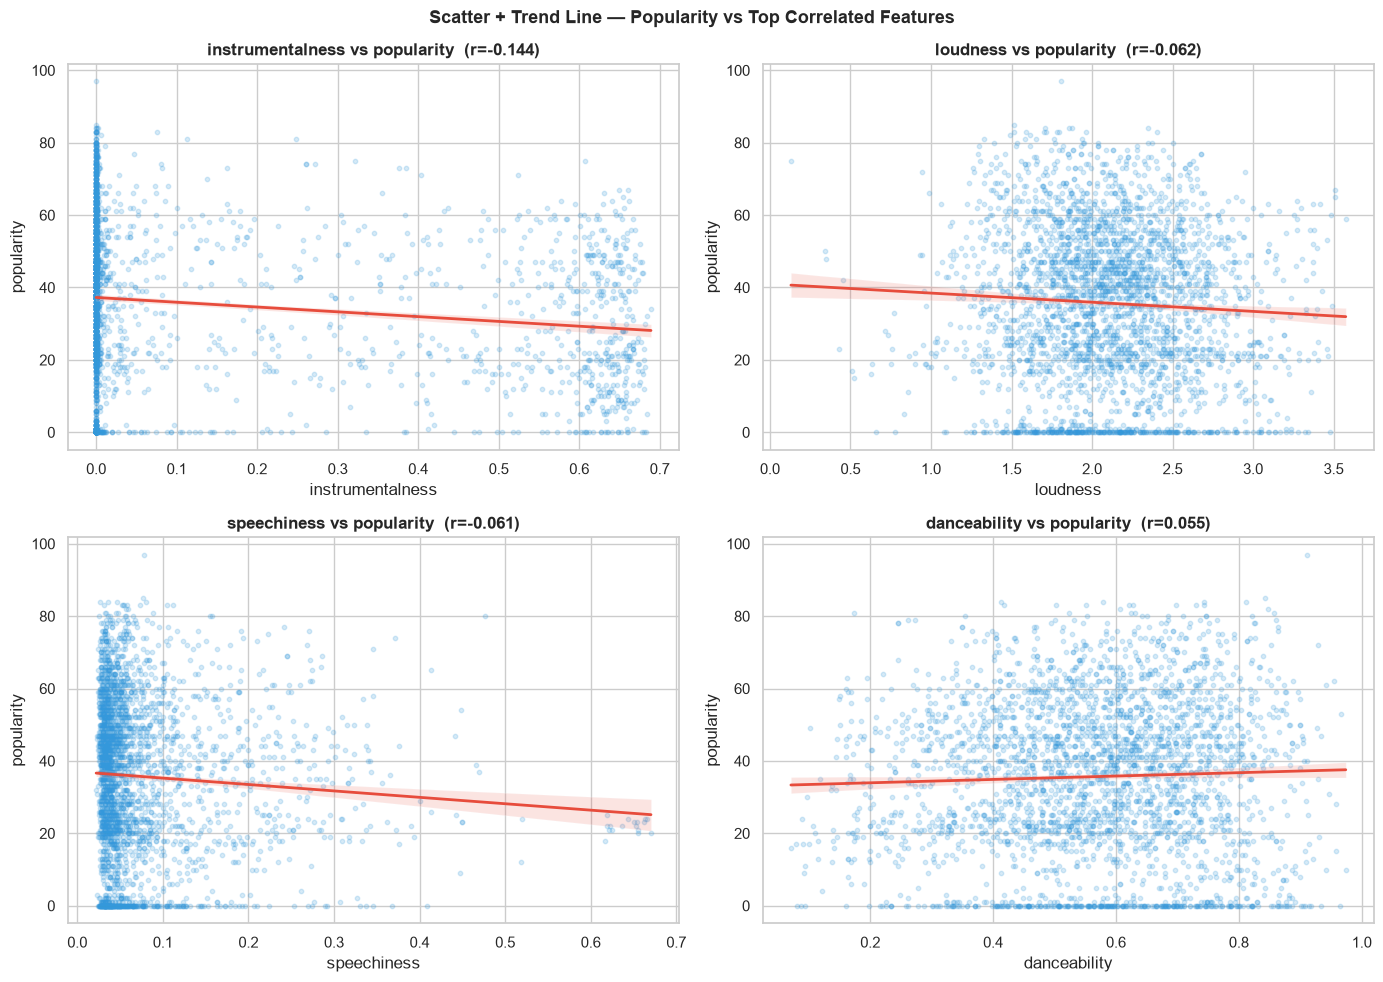

In [16]:
# ── Scatter + trend line: popularity vs top 4 correlated features ─────────
top4   = pop_corr.abs().sort_values(ascending=False).head(4).index.tolist()
sample = df[audio_features].sample(3000, random_state=42)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, feat in zip(axes.flatten(), top4):
    sns.regplot(data=sample, x=feat, y="popularity", ax=ax,
                scatter_kws={"alpha": 0.2, "s": 10, "color": "#3498db"},
                line_kws={"color": "#e74c3c", "linewidth": 2})
    r = corr_df.loc[feat, "popularity"]
    ax.set_title(f"{feat} vs popularity  (r={r:.3f})", fontweight="bold")

plt.suptitle("Scatter + Trend Line — Popularity vs Top Correlated Features",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [17]:
# ── Save encoded dataset ───────────────────────────────────────────────────
df.to_csv(ENCODED_DATA_PATH, index=False)
print(f"Encoded dataset saved to: {ENCODED_DATA_PATH.resolve()}")
print(f"Final shape: {df.shape}")
df.head()

Encoded dataset saved to: D:\entc_ml_project-master\entc_ml_project-master\archive\spotify_encoded.csv
Final shape: (105731, 129)


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,...,track_genre_spanish,track_genre_study,track_genre_swedish,track_genre_synth-pop,track_genre_tango,track_genre_techno,track_genre_trance,track_genre_trip-hop,track_genre_turkish,track_genre_world-music
0,73,12.348730,0,0.676,0.431133,1,2.047047,0,0.133656,0.031692,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,55,11.915794,0,0.420,0.606499,1,2.903288,1,0.073529,0.654406,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,57,12.258793,0,0.438,0.495306,0,2.373323,1,0.054204,0.190620,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,71,12.215696,0,0.266,0.662894,0,2.971132,1,0.035657,0.644482,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,82,12.200326,0,0.618,0.442761,2,2.368373,1,0.051263,0.384582,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
